# 01 · Data Preparation
**Owner: Rence**

Builds the cleaned dataset that every other notebook uses, then draws the two methodology figures:
- `fig01_dwell_cleaning.png`: dwell time before vs after cleaning
- `fig02_boardings_heatmap.png`: average weekday boardings by stop and hour

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from project import load_events, load_stops, new_fig, finish, save, COLORS, SEQ_CMAP, SOURCE_NOTE

## 1. Run the cleaning pipeline
`src/prepare_data.py` does: filter (6 rules) → convert types → remove duplicates → mark invalid values → impute (median of same stop and hour) → derive variables → save to `data/processed/`.

In [2]:
%run ../src/prepare_data.py

                                                                                       item   value
                                                                   Raw dataset (all routes) 9197694
                                                                             Route 801 only  547616
                                                             Bus serving its assigned route  524728
                                                                             No error flags  480452
                                                            Valid stop ID (both directions)  455654
                                                                   Southbound (direction 6)  229421
                                                      After removing duplicate stop records  229414
                                           Records in analysis window (weekdays 7:00-17:59)  126070
                                                                        Values imputed: ons      14


In [3]:
summary = pd.read_csv('../data/processed/cleaning_summary.csv')
summary

,item,value
0,Raw dataset (all routes),9197694
1,Route 801 only,547616
2,Bus serving its assigned route,524728
3,No error flags,480452
4,Valid stop ID (both directions),455654
5,Southbound (direction 6),229421
6,After removing duplicate stop records,229414
7,Records in analysis window (weekdays 7:00-17:59),126070
8,Values imputed: ons,14
9,Values imputed: offs,19


In [4]:
ev = load_events()
stops = load_stops()
print(ev.shape)
ev.head()

(229414, 20)


,service_day,arrival,hour,day_type,in_window,stop_id,stop_order,is_terminal,vehicle_id,trip_id,ons,offs,max_load,dwell_time,dwell_time_raw,headway_s,ons_imputed,offs_imputed,max_load_imputed,dwell_time_imputed
0,2021-06-30,2021-07-01 00:07:00,0,Weekday,False,4046,22,False,5005,2527337,1.0,2.0,9,16.0,16,NaN,False,False,False,False
1,2021-06-30,2021-07-01 00:08:58,0,Weekday,False,5870,23,False,5005,2527337,1.0,4.0,6,24.0,24,NaN,False,False,False,False
2,2021-06-30,2021-07-01 00:13:41,0,Weekday,False,5553,24,False,5005,2527337,0.0,2.0,4,17.0,17,NaN,False,False,False,False
3,2021-06-30,2021-07-01 00:18:58,0,Weekday,False,5872,27,False,5005,2527337,0.0,2.0,2,16.0,16,NaN,False,False,False,False
4,2021-06-30,2021-07-01 00:24:29,0,Weekday,False,5873,29,True,5005,2527337,0.0,1.0,1,NaN,17,NaN,False,False,False,False


## 2. Figure: dwell time before vs after cleaning
Before cleaning, dwell times reach several hours because buses sit at the two end stops (terminals) on layover. Cleaning removes terminal records and marks non-terminal dwell times above 10 minutes as invalid (then imputed).

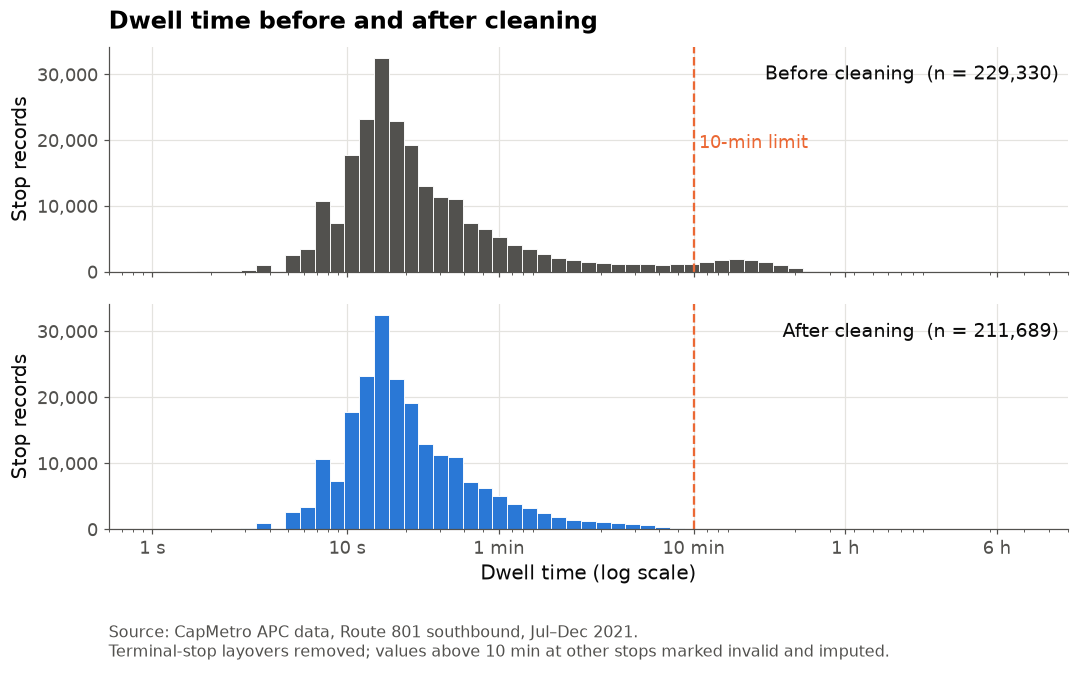

In [5]:
bins = np.logspace(0, np.log10(30000), 60)
before = ev.dwell_time_raw[ev.dwell_time_raw > 0]
after = ev.dwell_time.dropna()
after = after[after > 0]

fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
for ax, data, color, label in [(axes[0], before, COLORS['muted'], f'Before cleaning  (n = {len(before):,})'),
                               (axes[1], after, COLORS['blue'], f'After cleaning  (n = {len(after):,})')]:
    ax.hist(data, bins=bins, color=color, edgecolor='white', linewidth=0.6)
    ax.set_xscale('log')
    ax.set_ylabel('Stop records')
    ax.text(0.99, 0.92, label, transform=ax.transAxes, ha='right', va='top', fontsize=12.5, color=COLORS['text'])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
for ax in axes:
    ax.axvline(600, color=COLORS['orange'], linewidth=1.5, linestyle='--')
axes[0].text(640, axes[0].get_ylim()[1] * 0.55, '10-min limit', color=COLORS['orange'], fontsize=11.5)
ticks = [1, 10, 60, 600, 3600, 21600]
axes[1].set_xticks(ticks, ['1 s', '10 s', '1 min', '10 min', '1 h', '6 h'])
axes[0].set_title('Dwell time before and after cleaning')
axes[1].set_xlabel('Dwell time (log scale)')
axes[1].annotate(SOURCE_NOTE + '.\nTerminal-stop layovers removed; values above 10 min at other stops marked invalid and imputed.',
                 xy=(0, -0.42), xycoords='axes fraction', fontsize=10.5, color=COLORS['muted'], va='top')
fig.tight_layout()
save(fig, 'fig01_dwell_cleaning');

## 3. Figure: average weekday boardings by stop and hour

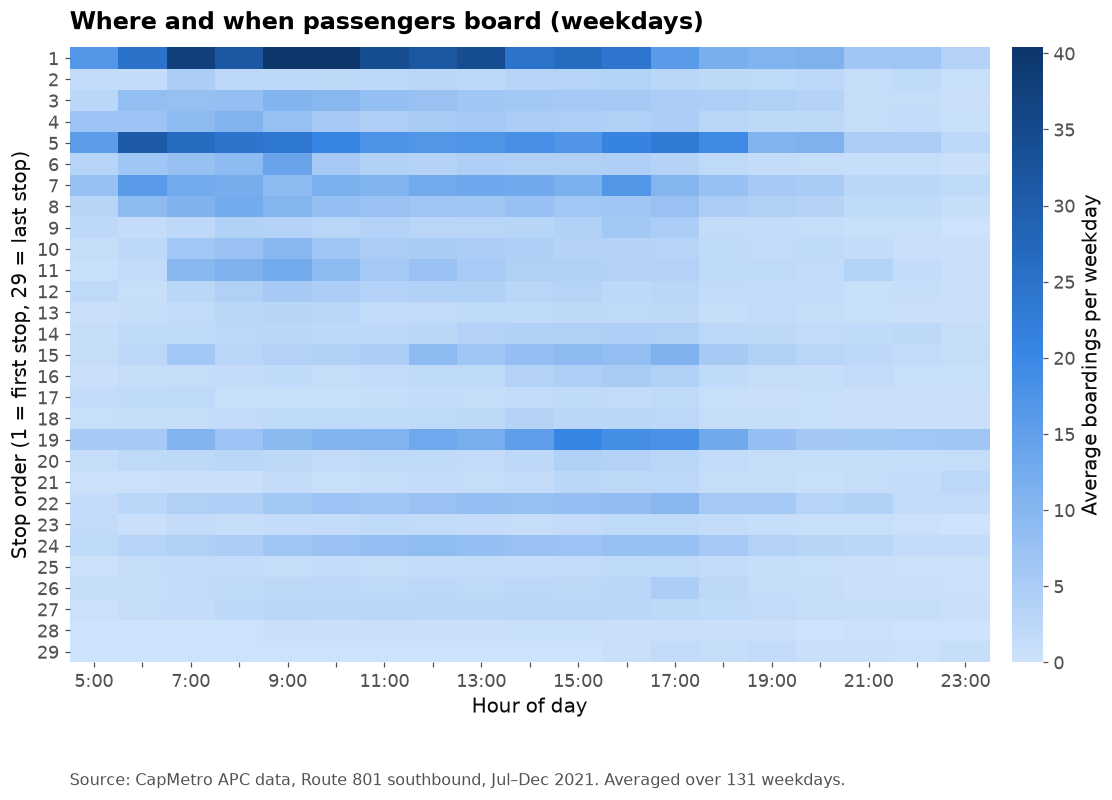

In [6]:
# drop service day 2021-06-30: it only holds 8 records (trips just after midnight), not a full day
wk = ev[(ev.day_type == 'Weekday') & (ev.service_day > '2021-06-30')]
n_days = wk.service_day.nunique()
grid = (wk.groupby(['stop_order', 'hour']).ons.sum() / n_days).unstack(fill_value=0)
grid = grid.loc[:, 5:23]   # service hours with meaningful ridership

fig, ax = plt.subplots(figsize=(11, 7.5))
im = ax.imshow(grid.values, aspect='auto', cmap=SEQ_CMAP, interpolation='nearest')
ax.set_xticks(range(len(grid.columns)), [f'{h}:00' if h % 2 == 1 else '' for h in grid.columns])
ax.set_yticks(range(len(grid.index)), grid.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=0.02)
cb.set_label('Average boardings per weekday')
cb.outline.set_visible(False)
finish(ax, 'Where and when passengers board (weekdays)', 'Hour of day',
       'Stop order (1 = first stop, 29 = last stop)',
       note=SOURCE_NOTE + f'. Averaged over {n_days} weekdays.')
fig.tight_layout()
save(fig, 'fig02_boardings_heatmap');

In [7]:
top = ((wk.groupby('stop_order').ons.sum() / n_days).sort_values(ascending=False).head(5).rename('avg weekday boardings').round(0)
       .to_frame().join(stops.set_index('stop_order')[['stop_id']]))
print(f'Busiest stops, whole-day boardings per weekday ({n_days} weekdays):'); print(top)
print('Busiest hour:', grid.sum(axis=0).idxmax(), ':00')

Busiest stops, whole-day boardings per weekday (131 weekdays):
            avg weekday boardings stop_id
stop_order                               
1                           442.0    5304
5                           329.0    4540
19                          204.0    5867
7                           183.0    5859
8                           119.0    5606
Busiest hour: 9 :00
